# YOLO Fine-tuning: 장난감 3개 부류 (airplane / car / figure)

**과제:** 3개 부류 데이터로 YOLO fine-tuning → 객체 감지·추적 5초 동영상 → GitHub 공개 → 결과보고서

| 부류 | 대상 |
|---|---|
| `airplane` | 비행기 모형 |
| `car` | F1 자동차 모형 |
| `figure` | 캐릭터 피규어 |

> 시작 전: **런타임 → 런타임 유형 변경 → T4 GPU** 선택

## 1. 환경 설정

In [1]:
!pip install -q ultralytics roboflow
import ultralytics, torch
ultralytics.checks()
print("GPU:", torch.cuda.is_available())

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)
GPU: True


## 2. 데이터셋 불러오기 (Roboflow)

In [2]:
!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("s-workspace-okkyj").project("toy-detection-hf5yp")
version = project.version(1)
dataset = version.download("yolov8")

DATA_DIR = dataset.location
print(DATA_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to toy-detection-1 in yolov8:: 100%|██████████| 1085/1085 [00:00<00:00, 9834.78it/s]

/content/toy-detection-1


### 2-1. data.yaml 경로 정리 & 데이터 수 확인 (경로 오류 예방)

In [3]:
import yaml, os, glob
yaml_path = f"{DATA_DIR}/data.yaml"
cfg = yaml.safe_load(open(yaml_path))
cfg["path"]  = DATA_DIR
cfg["train"] = "train/images"
cfg["val"]   = "valid/images"
cfg["test"]  = "test/images" if os.path.isdir(f"{DATA_DIR}/test/images") else cfg.get("val")
yaml.safe_dump(cfg, open(yaml_path, "w"), allow_unicode=True)
print("classes:", cfg["names"])

for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"{DATA_DIR}/{split}/images/*"))
    print(f"{split:6s}: {n}장")

classes: ['airplane', 'car', 'figure']
train : 472장
valid : 45장
test  : 23장


In [4]:
# 부류별 객체(박스) 수 — 보고서용
from collections import Counter
names = cfg["names"]
cnt = Counter()
for f in glob.glob(f"{DATA_DIR}/*/labels/*.txt"):
    for line in open(f):
        if line.strip():
            cnt[int(line.split()[0])] += 1
for i, n in sorted(cnt.items()):
    print(f"{names[i]:10s}: {n}개")

airplane  : 181개
car       : 294개
figure    : 209개


## 3. Fine-tuning
COCO로 사전학습된 `yolov8n.pt`의 가중치를 가져와 3개 부류로 다시 학습한다 (전이학습).
- 더 높은 성능을 원하면 `yolov8s.pt`, 또는 최신 `yolo11n.pt` 로 바꿔 비교

In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
results = model.train(
    data=yaml_path,
    epochs=50,        # 데이터가 적으면 50~100
    imgsz=640,
    batch=16,
    patience=20,      # 개선 없으면 조기 종료
    name="toy3",
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/toy-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=toy3, nbs=64, nms=None, opset=None, optimize=False, op

## 4. 성능 평가

In [6]:
best = YOLO("runs/detect/toy3/weights/best.pt")
metrics = best.val(data=yaml_path, split="test")

print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")
print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")
print("\n부류별 mAP50-95")
for i, ap in enumerate(metrics.box.maps[:len(names)]):
    print(f"  {names[i]:10s}: {ap:.3f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 979.9±494.7 MB/s, size: 32.9 KB)
val: Scanning /content/toy-detection-1/test/labels... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 1.9Kit/s 0.0s
val: New cache created: /content/toy-detection-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1it/s 0.6s
                   all         23         30      0.994          1      0.995      0.972
              airplane          9          9      0.992          1      0.995      0.995
                   car         12         12      0.996          1      0.995      0.937
                figure          9          9      0.993          1      0.995      0.983
Speed: 2.1ms preprocess, 8.3ms inference, 0.1ms loss, 1.3ms postprocess per 

results.png


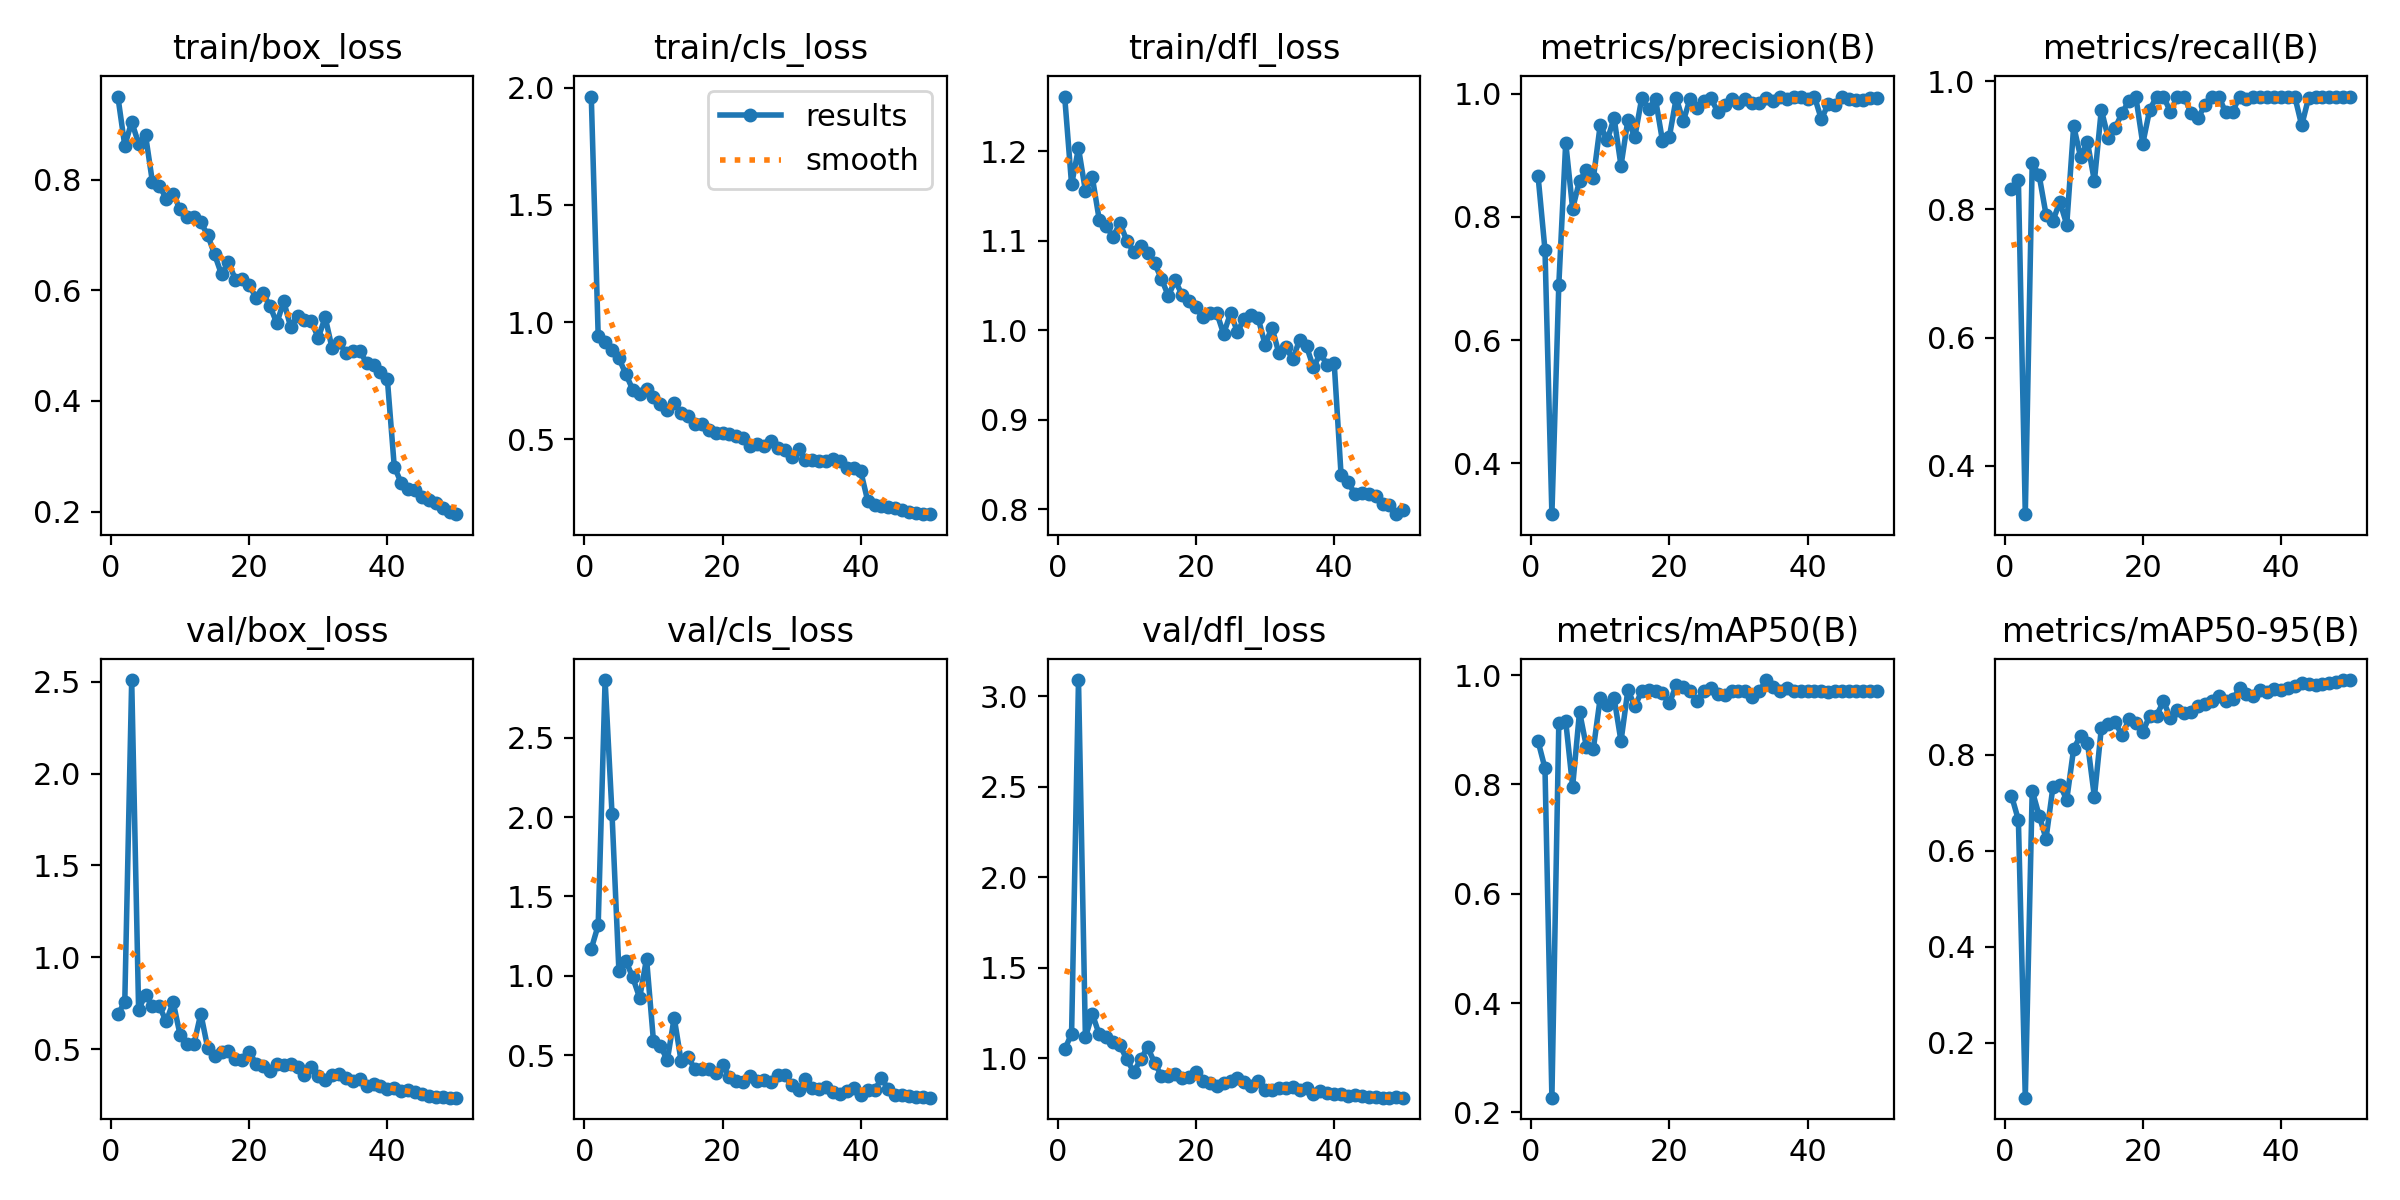

confusion_matrix.png


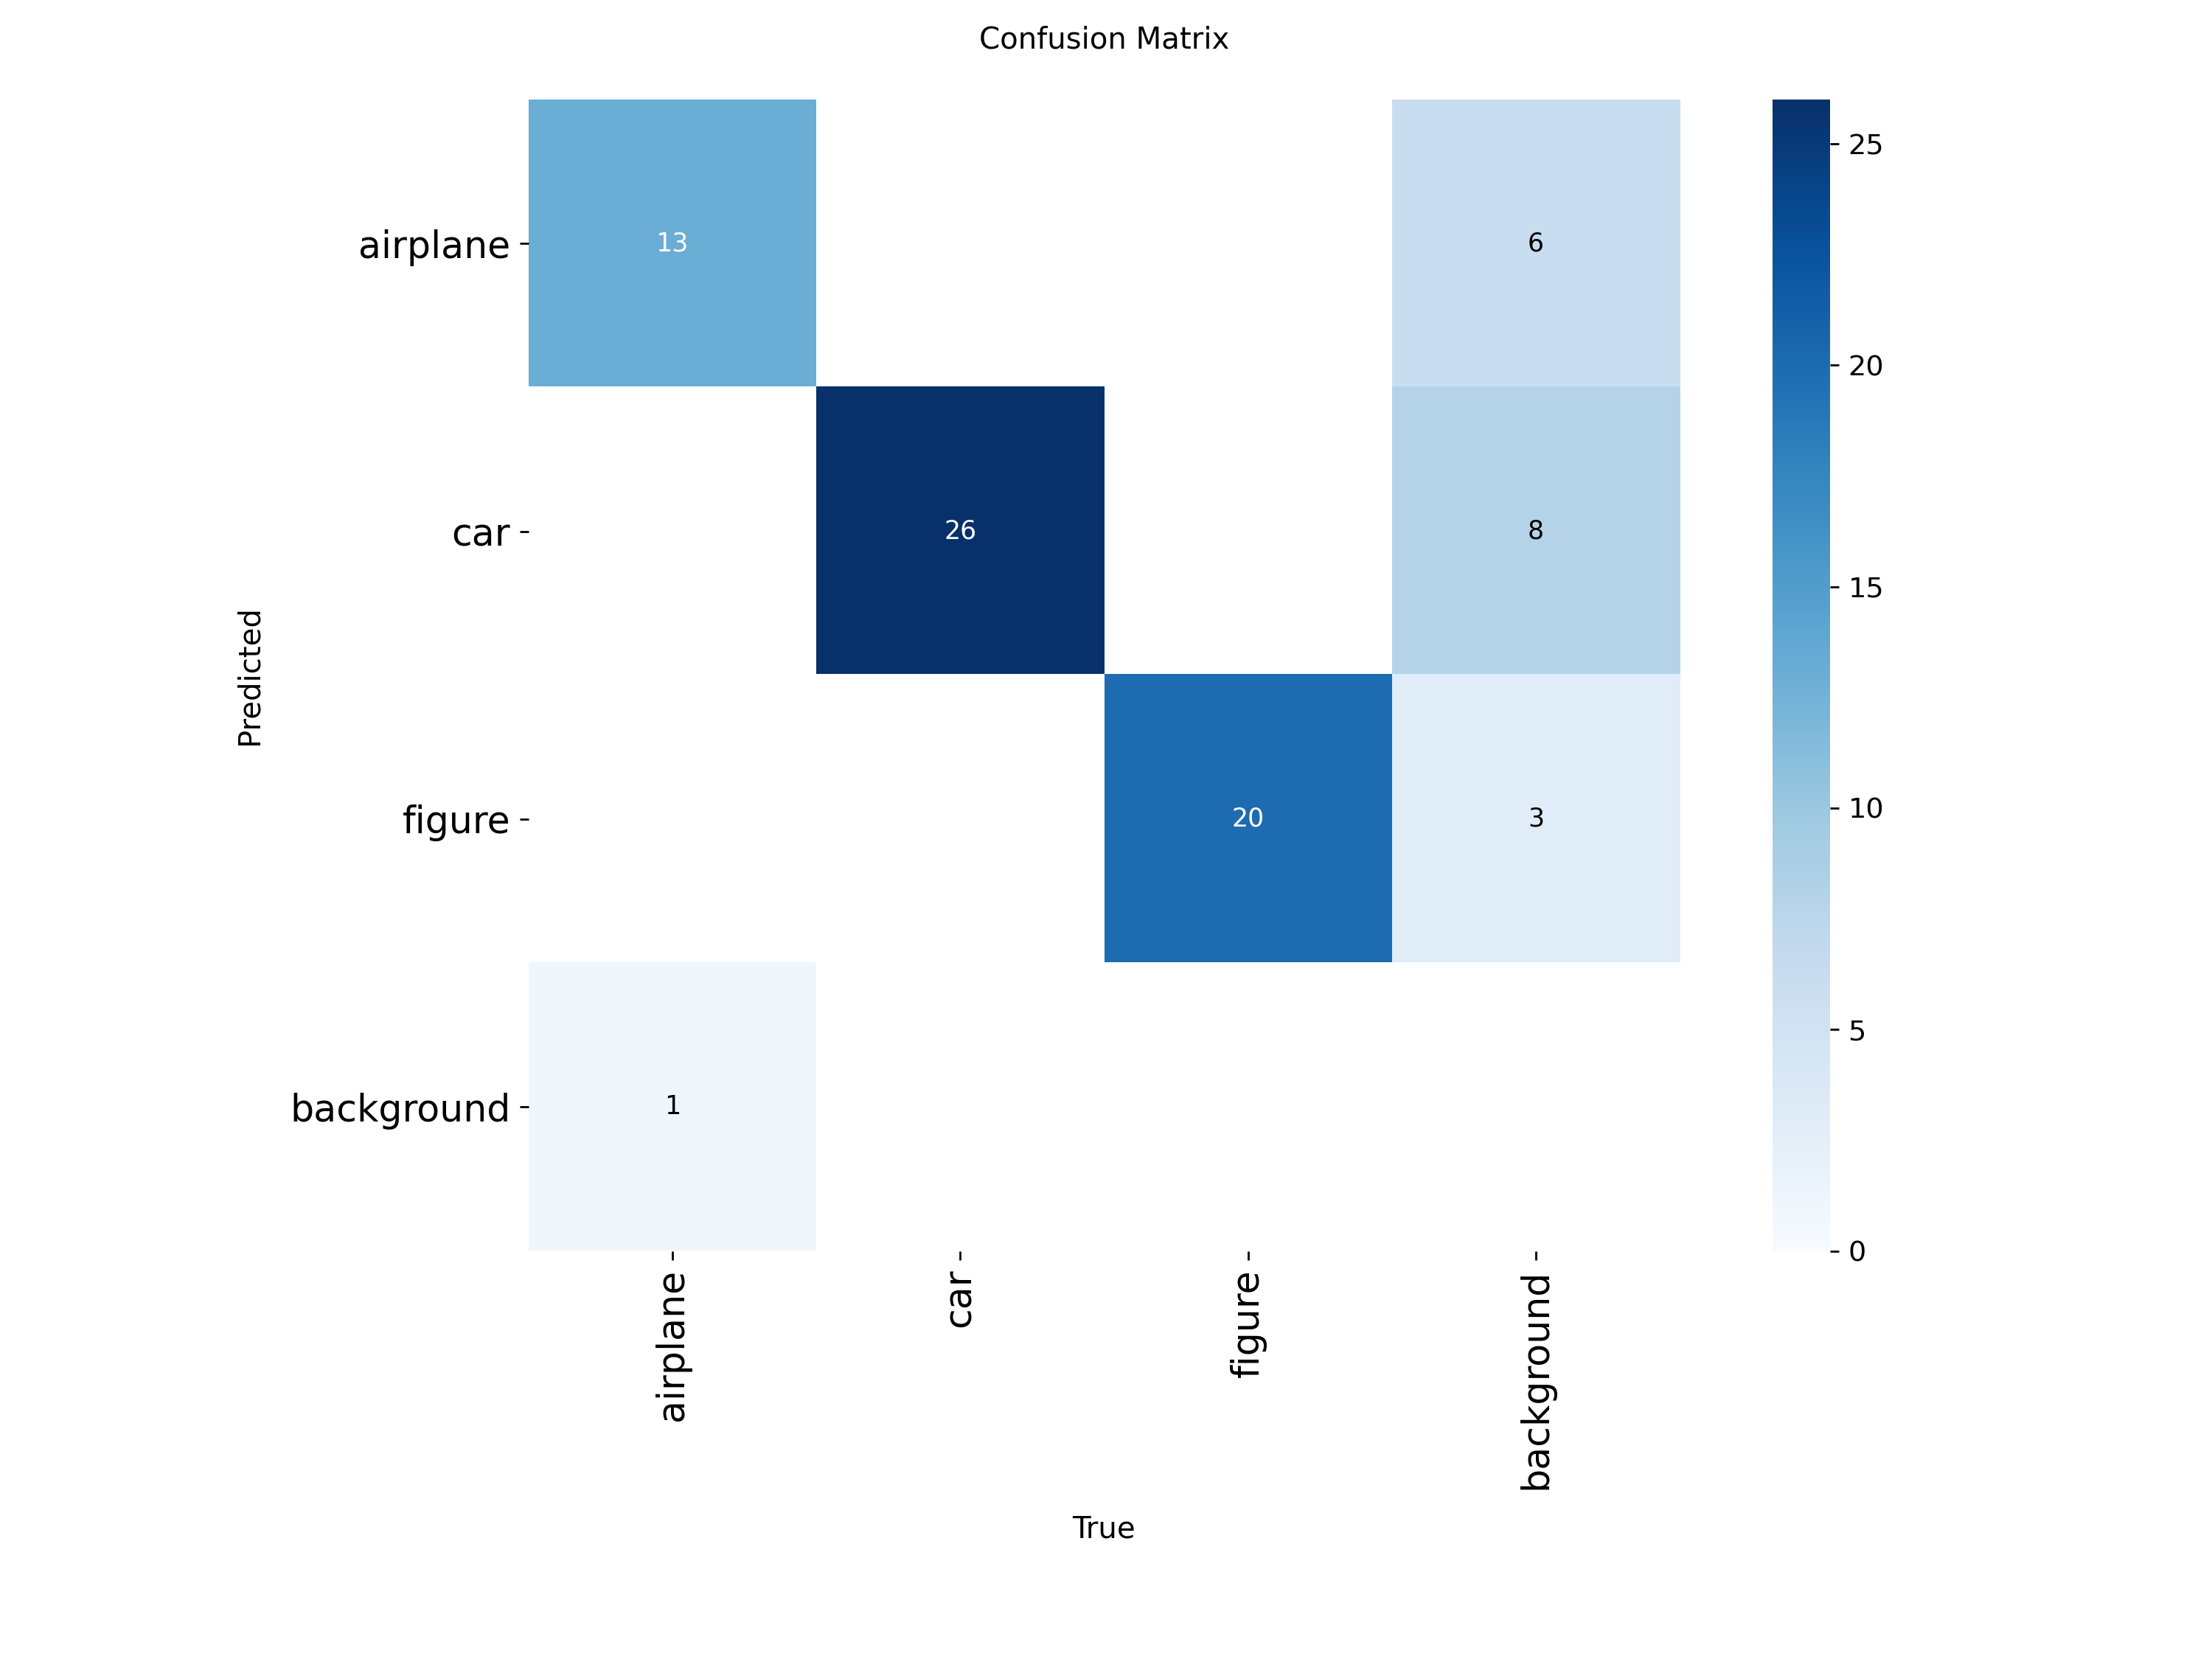

BoxPR_curve.png


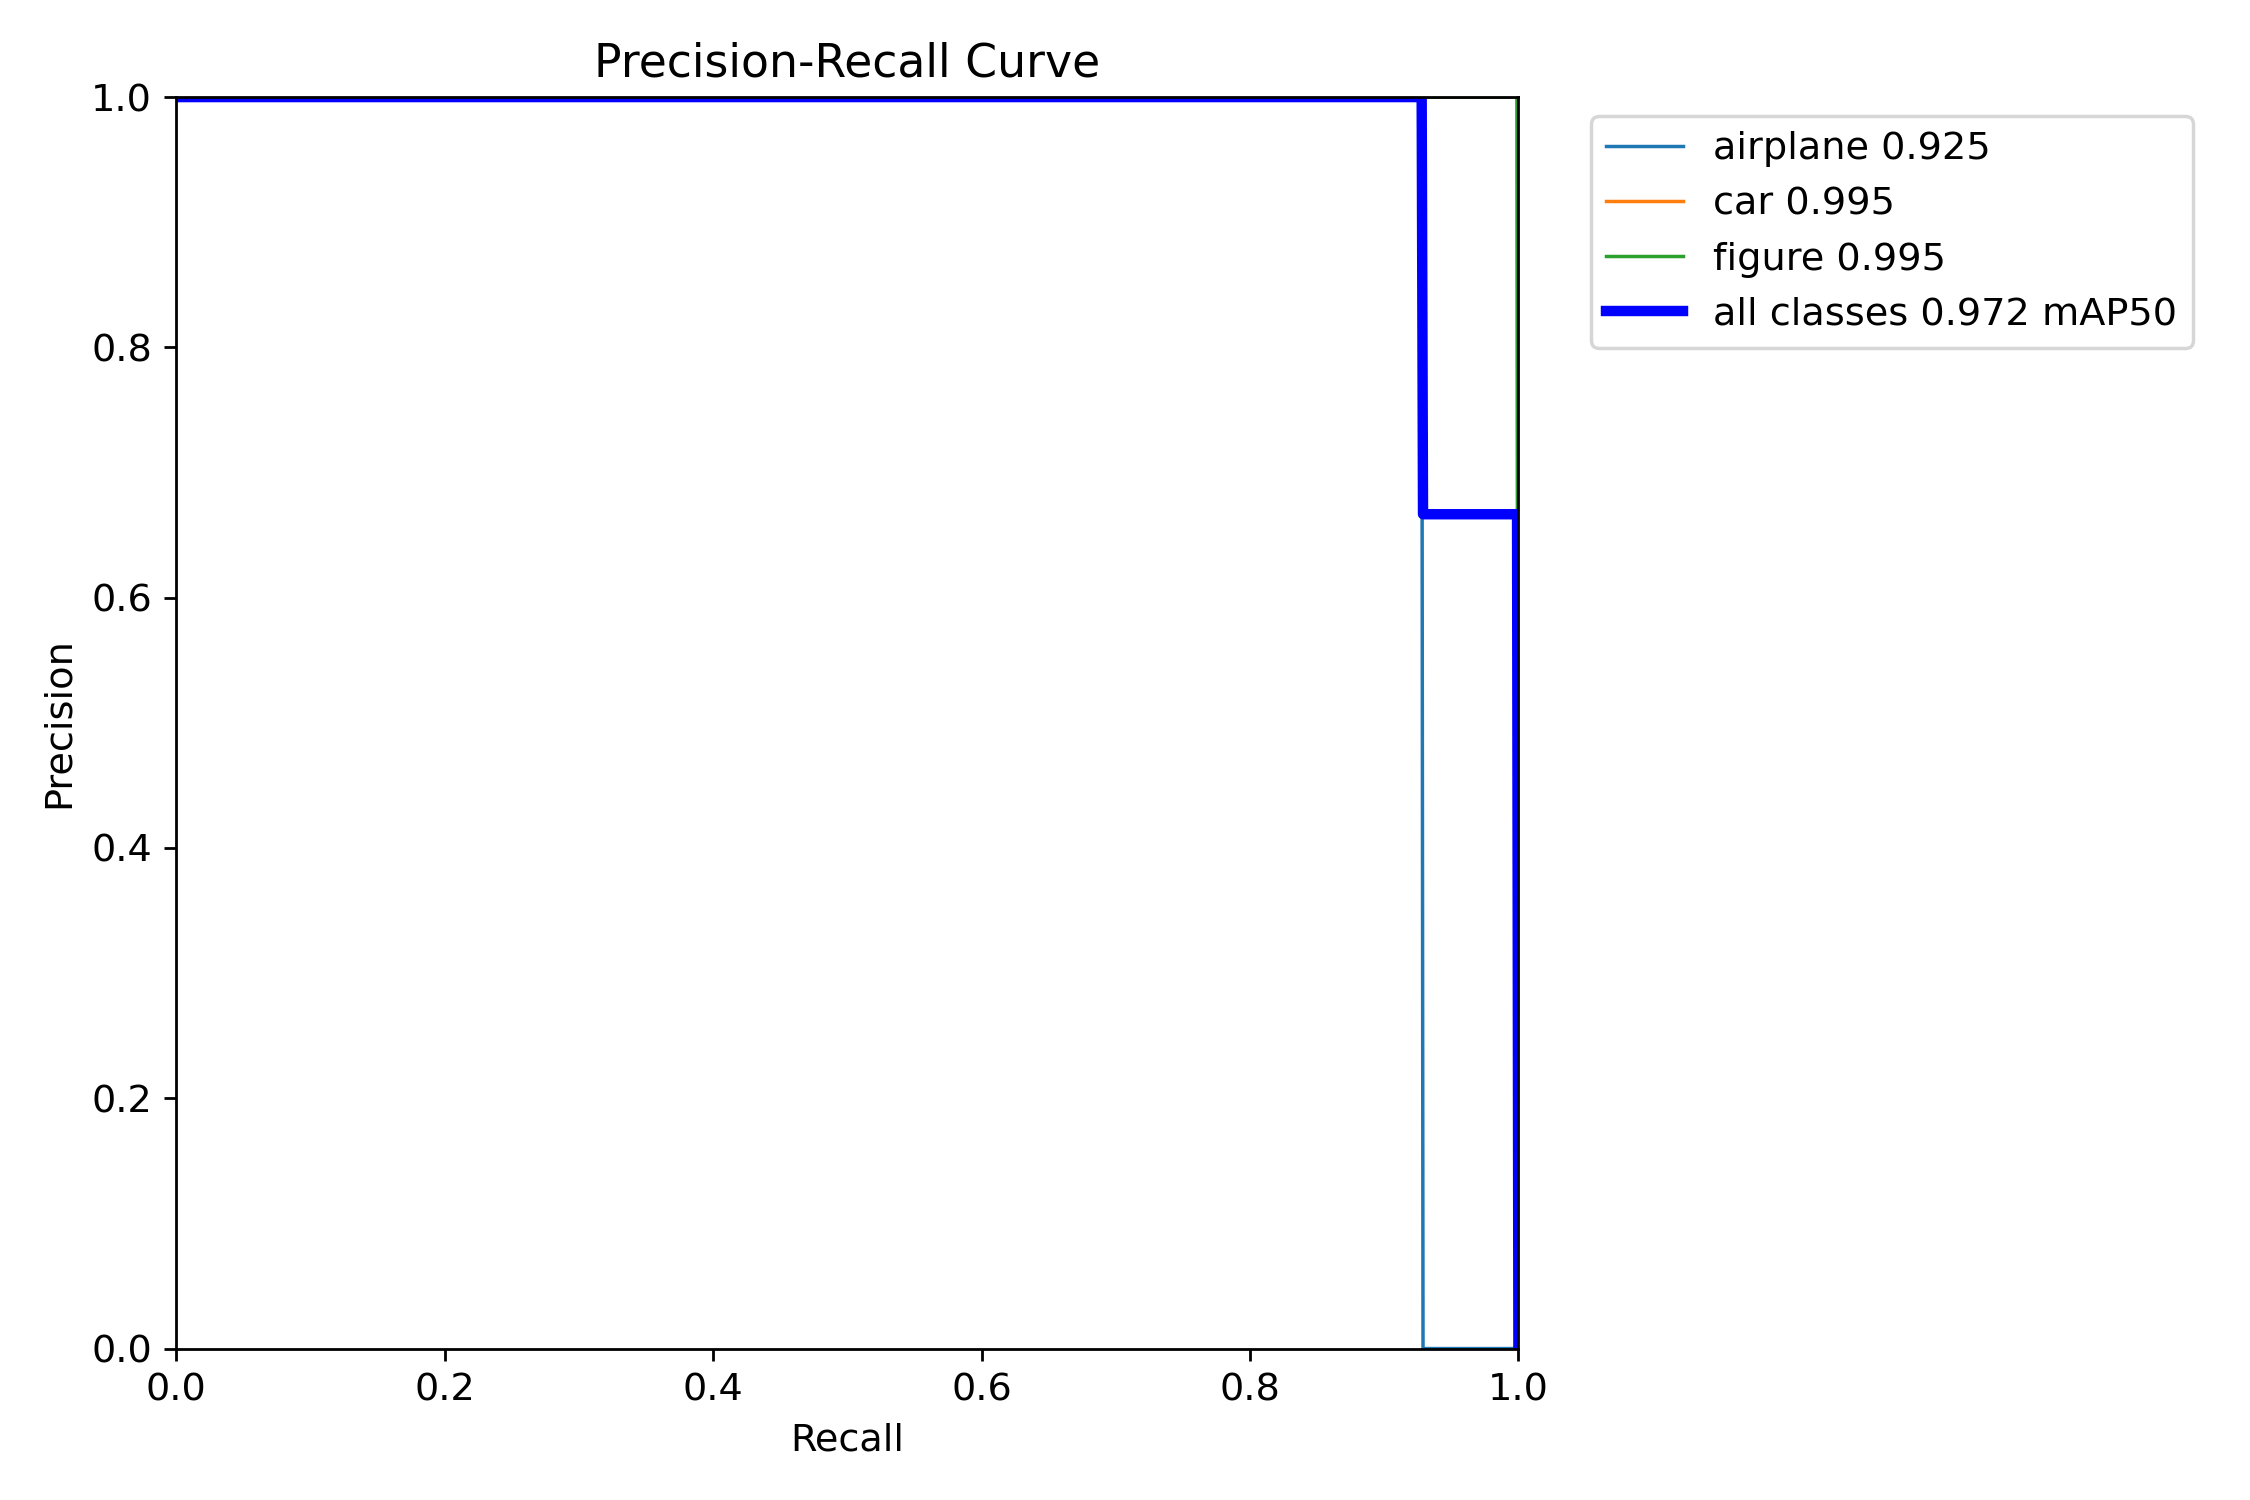

val_batch0_pred.jpg


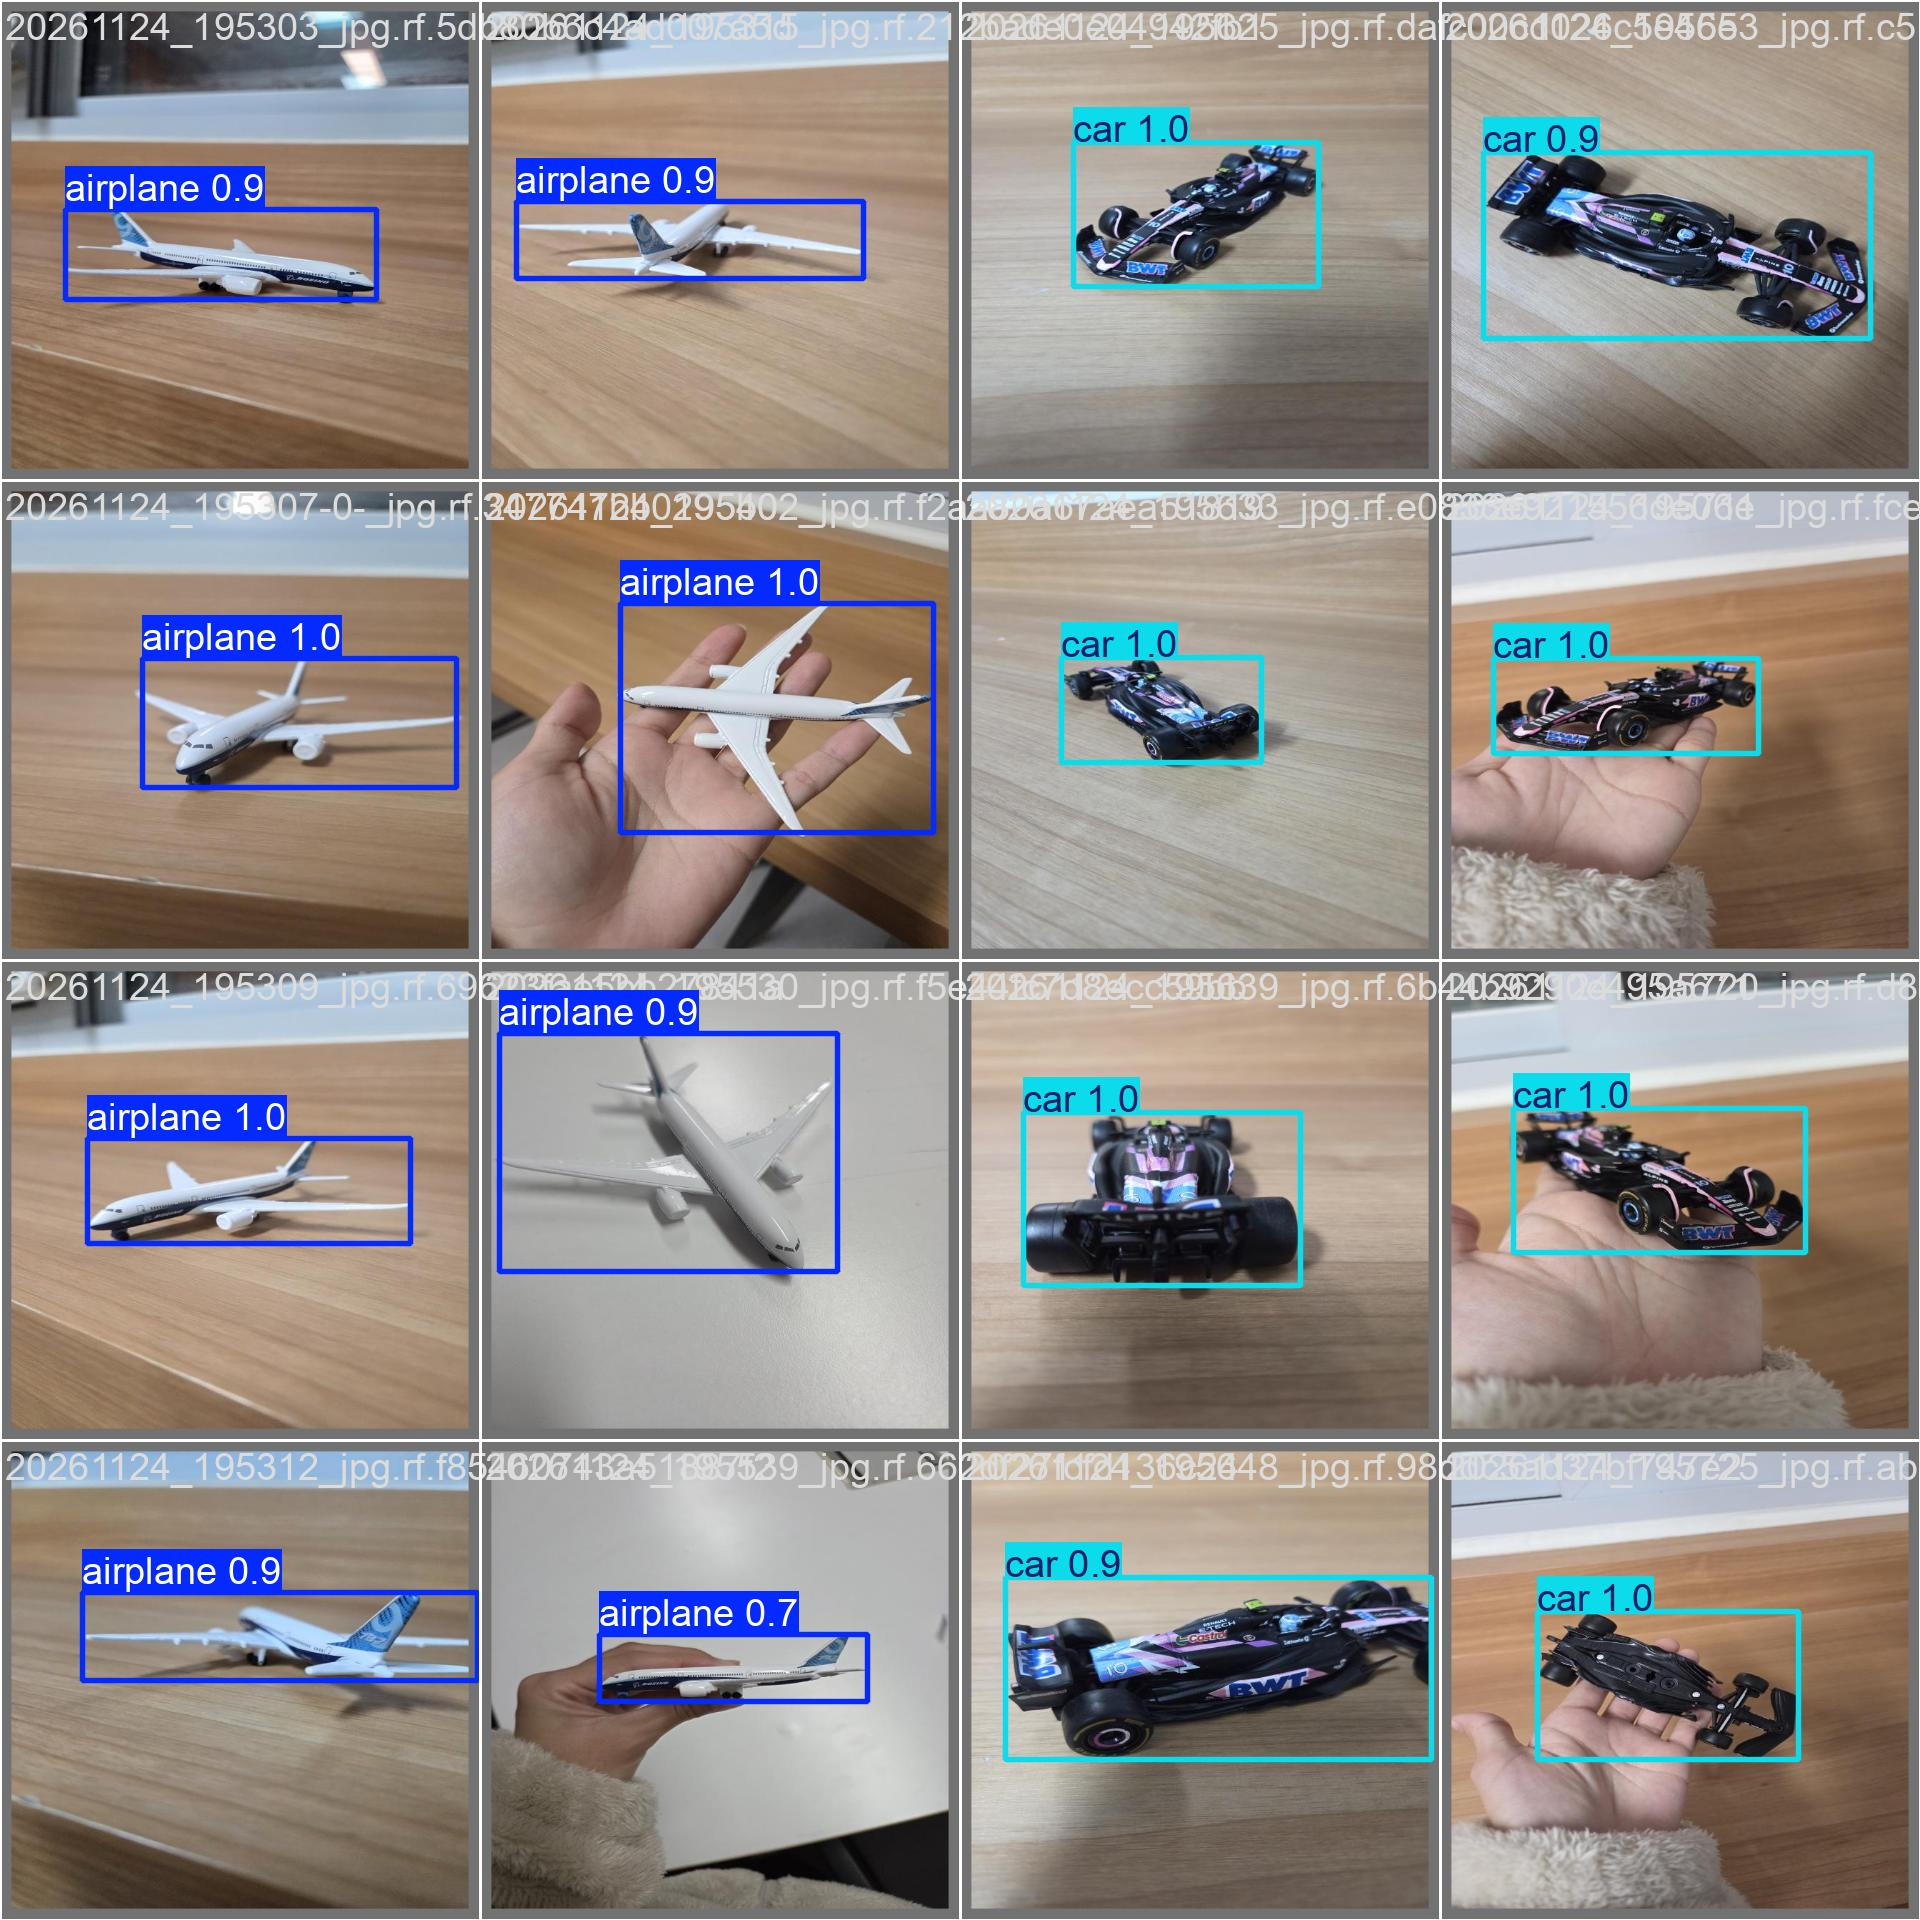

val_batch1_pred.jpg


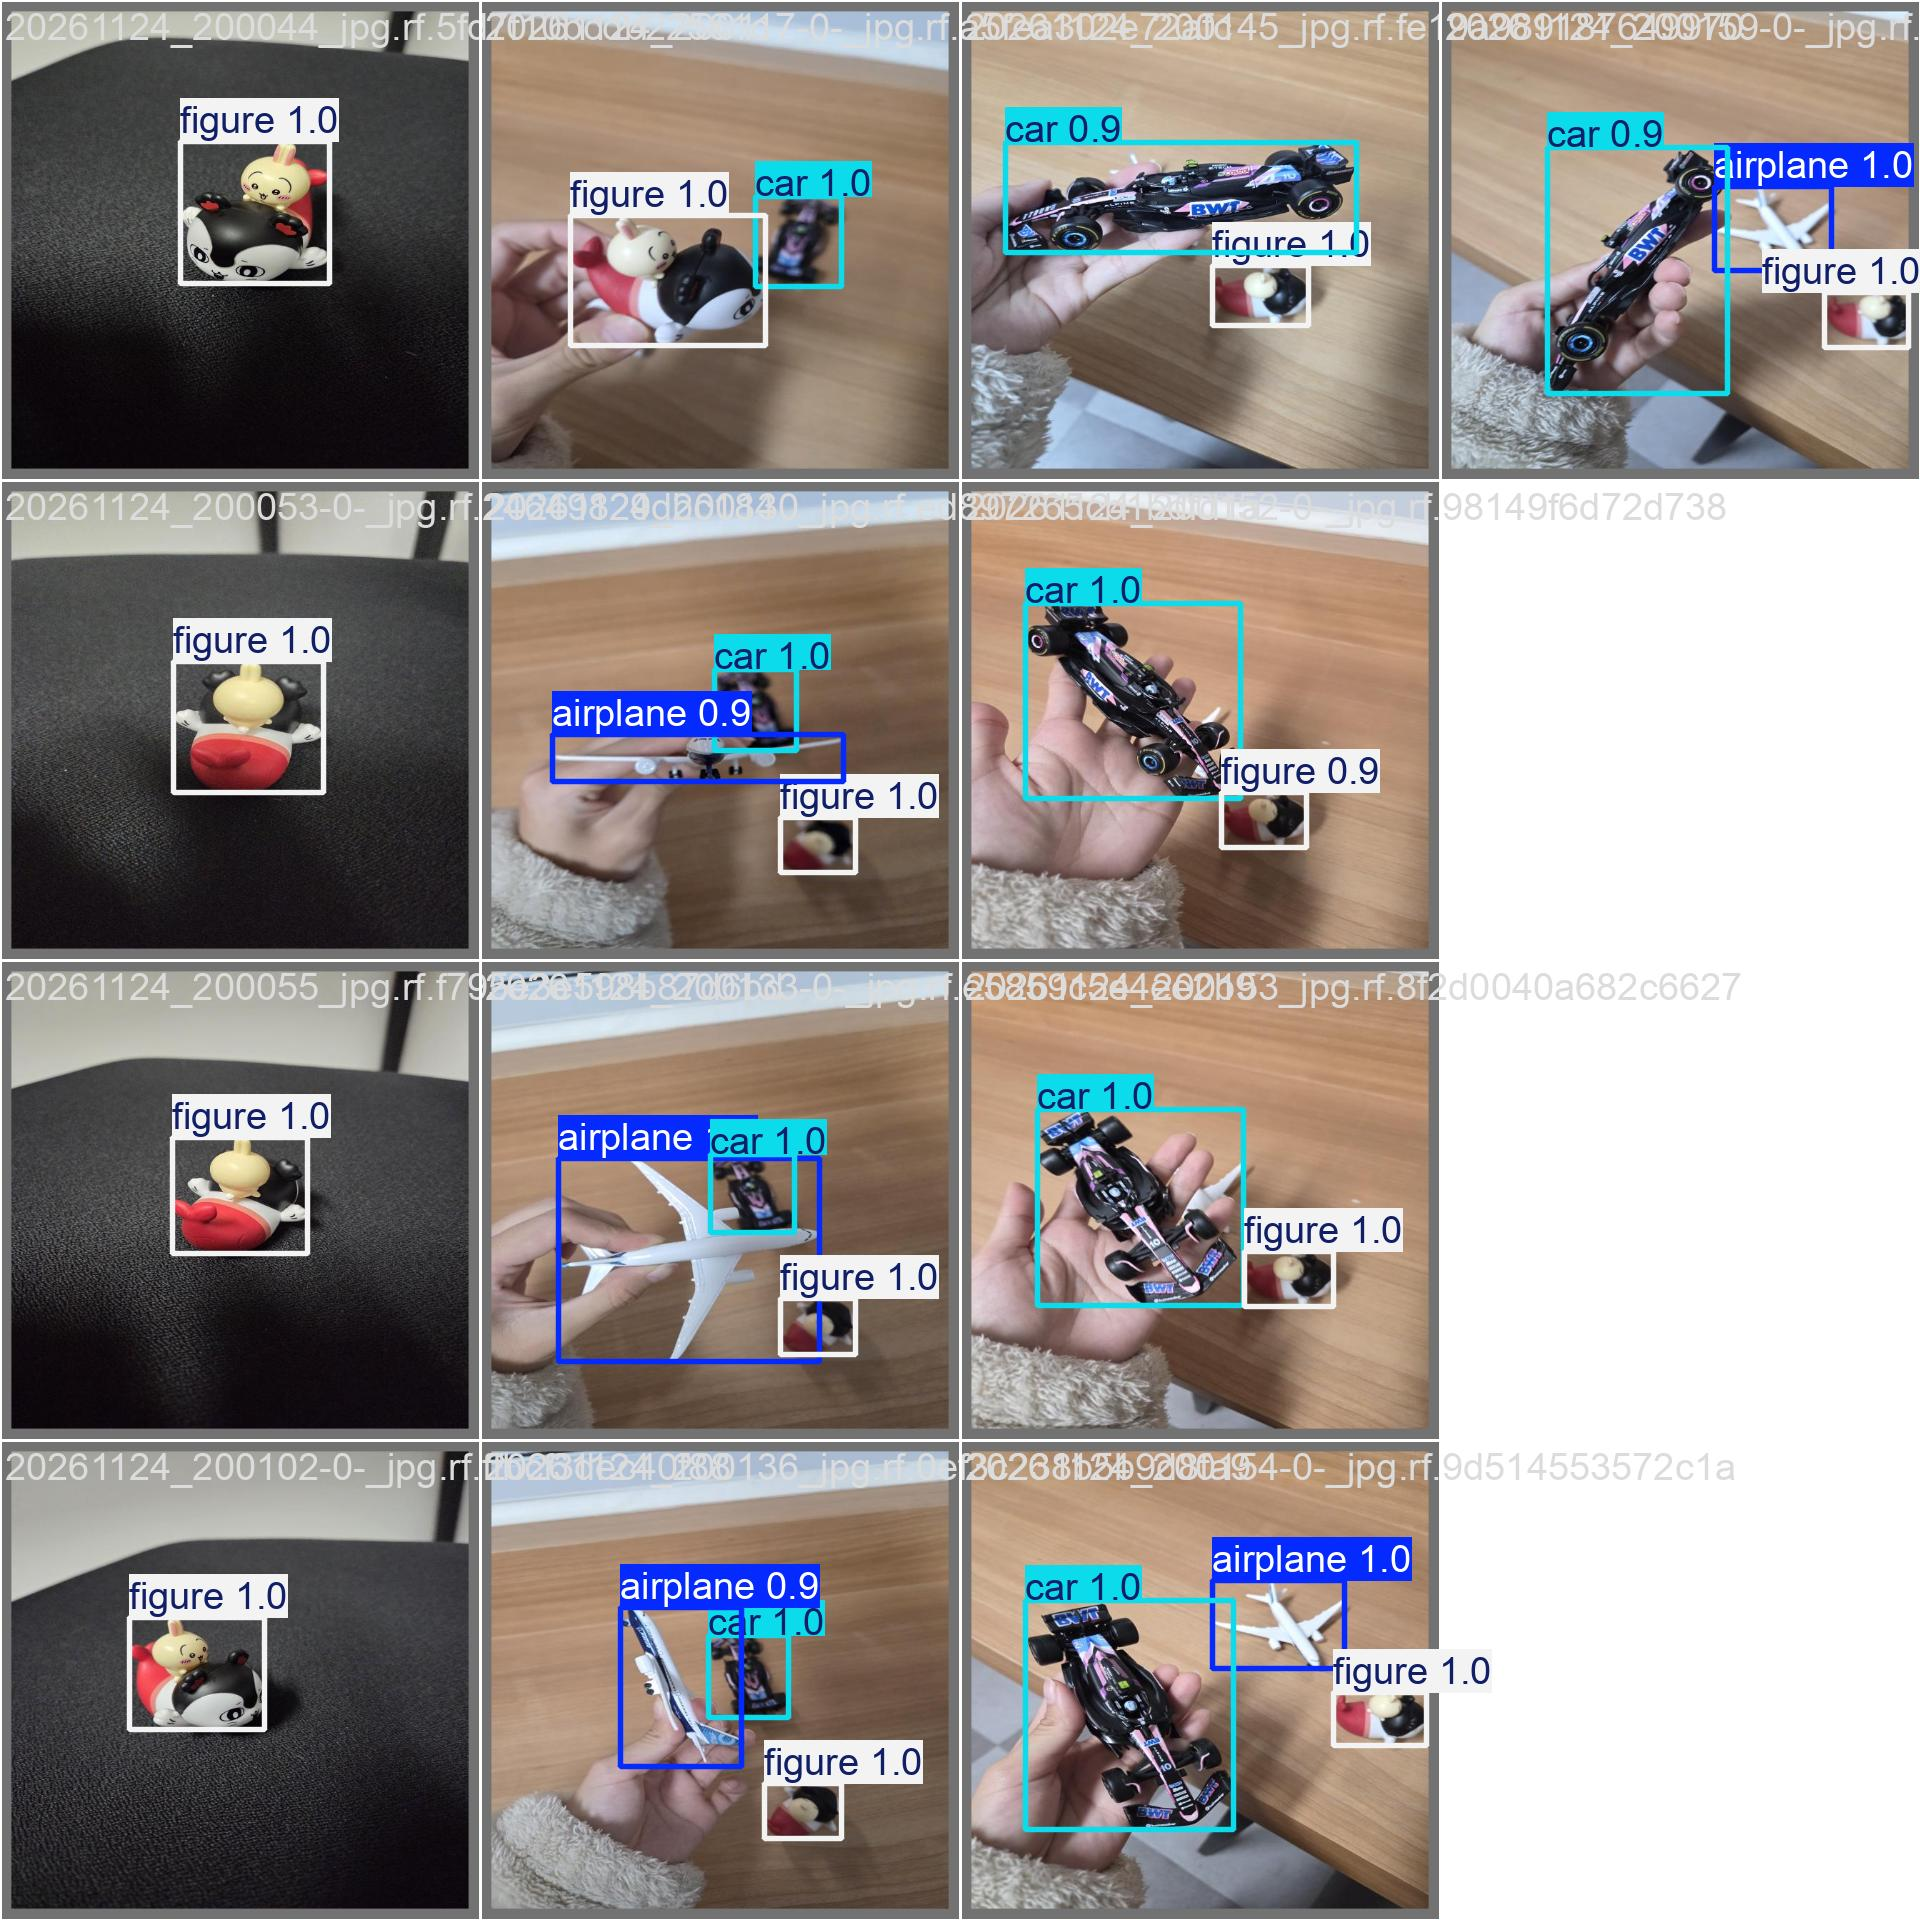

In [7]:
# 학습 곡선 / confusion matrix / PR curve / 예측 예시 보기
import os
from IPython.display import Image, display

run = "runs/detect/toy3"
for f in ["results.png", "confusion_matrix.png", "BoxPR_curve.png",
          "val_batch0_pred.jpg", "val_batch1_pred.jpg", "val_batch2_pred.jpg"]:
    p = f"{run}/{f}"
    if os.path.exists(p):
        print(f)
        display(Image(p, width=800))

## 5. 객체 감지 + 추적 동영상 만들기
1. 휴대폰으로 세 장난감이 나오는 영상을 5~10초 촬영
2. 왼쪽 파일 패널에 `my_video.mp4` 로 업로드

In [8]:
best.track(
    source="my_video.mp4",
    tracker="bytetrack.yaml",
    conf=0.4,
    save=True,
    name="toy3_track",
)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 178ms
Prepared 1 package in 39ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/155) /content/my_video.mp4: 384x640 1 airplane, 1 car, 1 figure, 6.2ms
video 1/1 (f

In [9]:
# 결과 영상 찾기 → 5초로 자르고 mp4(H.264)로 변환
out = sorted(glob.glob("runs/detect/toy3_track*/*.*"), key=os.path.getmtime)[-1]
print("결과 파일:", out)
!ffmpeg -y -loglevel error -i "{out}" -t 5 -c:v libx264 -pix_fmt yuv420p -an result_5s.mp4
print("완료: result_5s.mp4")

결과 파일: runs/detect/toy3_track/my_video.avi
완료: result_5s.mp4


In [10]:
# 노트북에서 바로 재생
from IPython.display import HTML
from base64 import b64encode
mp4 = b64encode(open("result_5s.mp4", "rb").read()).decode()
HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{mp4}" type="video/mp4"></video>')

## 6. 제출 파일 정리 & 다운로드
GitHub 저장소에 올릴 파일을 한 폴더에 모은다.

In [11]:
import shutil
os.makedirs("submit/results", exist_ok=True)
shutil.copy(f"{run}/weights/best.pt", "submit/best.pt")
shutil.copy("result_5s.mp4", "submit/result_5s.mp4")
for f in ["results.png", "confusion_matrix.png", "BoxPR_curve.png", "val_batch0_pred.jpg", "val_batch1_pred.jpg", "results.csv"]:
    if os.path.exists(f"{run}/{f}"):
        shutil.copy(f"{run}/{f}", f"submit/results/{f}")
shutil.make_archive("submit", "zip", "submit")

from google.colab import files
files.download("submit.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>